# 01 — Data Exploration

Milestone 1 (session wrap-up): load historical adjusted close prices, inspect coverage, and compute simple/log returns.

**Note:** Yahoo Finance downloads can time out. This notebook prefers the local cache at `data/cache/prices_close.csv`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Allow importing from ../src when the notebook runs from notebooks/
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_loader import (
    DEFAULT_BENCHMARK,
    DEFAULT_START,
    DEFAULT_TICKERS,
    load_or_download,
)

TICKERS = DEFAULT_TICKERS
BENCHMARK = DEFAULT_BENCHMARK
ALL_TICKERS = TICKERS + [BENCHMARK]
START = DEFAULT_START

print("Project root:", PROJECT_ROOT)
print("Universe:", ALL_TICKERS)

Project root: D:\quant portfolio\smart-portfolio-lab
Universe: ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'KO', 'WMT', 'JPM', 'XOM', 'JNJ', 'SPY']


## Load prices

Uses the cached CSV by default. Set `refresh=True` only when you want to re-download from Yahoo Finance.

In [2]:
prices = load_or_download(
    tickers=ALL_TICKERS,
    start=START,
    refresh=False,  # set True to force a fresh Yahoo download
)

print("shape:", prices.shape)
print("date range:", prices.index.min().date(), "→", prices.index.max().date())
print("missing values per ticker:")
print(prices.isna().sum())
prices.head()

shape: (1717, 10)
date range: 2020-01-02 → 2026-10-30
missing values per ticker:
AAPL    0
MSFT    0
NVDA    0
AMZN    0
KO      0
WMT     0
JPM     0
XOM     0
JNJ     0
SPY     0
dtype: int64


,AAPL,MSFT,NVDA,AMZN,KO,WMT,JPM,XOM,JNJ,SPY
Date,,,,,,,,,,
2020-01-02,72.271545,151.544266,5.957138,94.900497,44.873505,36.203289,117.313950,52.606388,121.338539,295.391693
2020-01-03,71.568916,149.657257,5.861788,93.748497,44.628689,35.883690,115.765793,52.183475,119.933678,293.154968
2020-01-06,72.139168,150.044144,5.886369,95.143997,44.612366,35.810627,115.673767,52.584148,119.784081,294.273376
2020-01-07,71.799934,148.676056,5.957635,95.343002,44.269634,35.478859,113.707253,52.153793,120.515602,293.445953
2020-01-08,72.954926,151.044205,5.968809,94.598503,44.351234,35.357101,114.594269,51.367298,120.498932,295.009918


## Quick price chart

Normalized to 1.0 at the first date so different price levels are comparable.

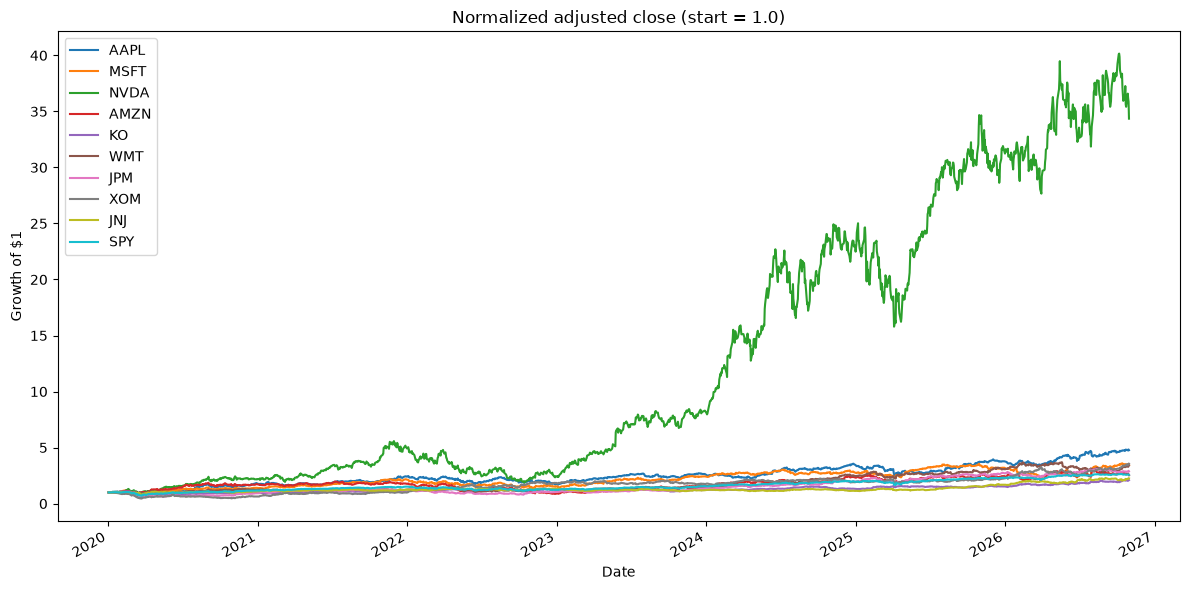

In [6]:
normalized = prices / prices.iloc[0]

ax = normalized.plot(figsize=(12, 6), title="Normalized adjusted close (start = 1.0)")
ax.set_ylabel("Growth of $1")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

## Returns

- **Simple return:** $r_t = P_t / P_{t-1} - 1$ (portfolio math uses these)
- **Log return:** $\log(P_t / P_{t-1})$ (handy for compounding / stats)

The first row is NaN because there is no previous price.

In [7]:
simple_returns = prices.pct_change()
log_returns = np.log(prices / prices.shift(1))

summary = pd.DataFrame({
    "mean_daily_simple": simple_returns.mean(),
    "std_daily_simple": simple_returns.std(),
    "ann_return_approx": simple_returns.mean() * 252,
    "ann_vol_approx": simple_returns.std() * np.sqrt(252),
})

summary.round(4)

,mean_daily_simple,std_daily_simple,ann_return_approx,ann_vol_approx
AAPL,0.0011,0.0196,0.2778,0.3112
MSFT,0.0009,0.0191,0.2272,0.3024
NVDA,0.0026,0.0325,0.6518,0.5154
AMZN,0.0008,0.0224,0.1996,0.3560
KO,0.0005,0.0127,0.1293,0.2023
WMT,0.0008,0.0148,0.2079,0.2351
JPM,0.0008,0.0191,0.2010,0.3038
XOM,0.0009,0.0203,0.2385,0.3223
JNJ,0.0006,0.0125,0.1389,0.1988
SPY,0.0006,0.0126,0.1580,0.1996


## Correlation of daily simple returns

Diversification works better when assets do not all move together.

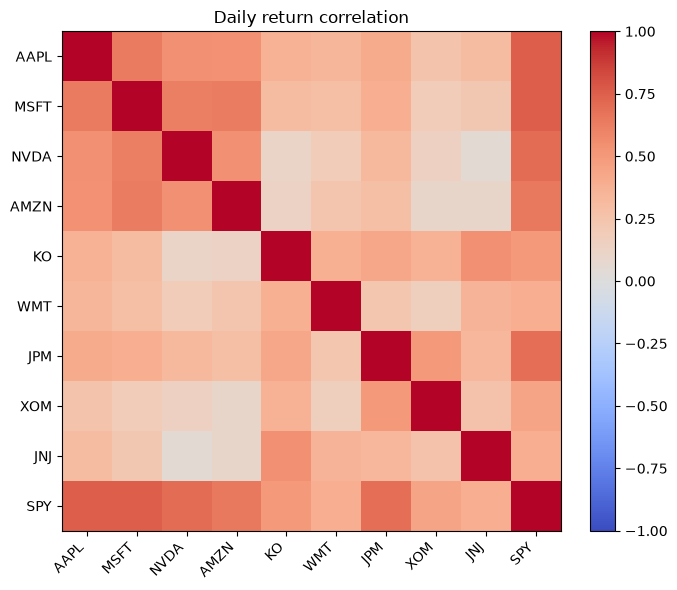

,AAPL,MSFT,NVDA,AMZN,KO,WMT,JPM,XOM,JNJ,SPY
AAPL,1.00,0.63,0.54,0.53,0.37,0.34,0.40,0.26,0.30,0.75
MSFT,0.63,1.00,0.62,0.63,0.30,0.28,0.39,0.19,0.22,0.75
NVDA,0.54,0.62,1.00,0.55,0.11,0.18,0.33,0.15,0.05,0.70
AMZN,0.53,0.63,0.55,1.00,0.13,0.24,0.28,0.10,0.09,0.65
KO,0.37,0.30,0.11,0.13,1.00,0.38,0.43,0.37,0.54,0.49
WMT,0.34,0.28,0.18,0.24,0.38,1.00,0.23,0.16,0.36,0.39
JPM,0.40,0.39,0.33,0.28,0.43,0.23,1.00,0.50,0.33,0.69
XOM,0.26,0.19,0.15,0.10,0.37,0.16,0.50,1.00,0.26,0.44
JNJ,0.30,0.22,0.05,0.09,0.54,0.36,0.33,0.26,1.00,0.39
SPY,0.75,0.75,0.70,0.65,0.49,0.39,0.69,0.44,0.39,1.00


In [ ]:
corr = simple_returns.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
ax.set_title("Daily return correlation")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

corr.round(2)

## Session checkpoint

Done today:
- Project setup + virtualenv
- Price universe defined (9 stocks + SPY)
- Cached adjusted closes loaded
- Simple/log returns + basic summary + correlation

Next session:
- Equal-weight baseline portfolio vs SPY
- Risk metrics (Sharpe, max drawdown)
- Minimum-variance / max-Sharpe optimizers